# NLP Sentence Similarity — Tech Persona (rebuilt pipeline)

**What changed from the original version** (see README.md for the full list):

- `bert_serving` / `BertClient` is gone. Embeddings come from a **pinned
  sentence-transformers checkpoint** (`sentence-transformers/all-MiniLM-L6-v2`,
  revision pinned in `sentence_similarity.py`), using its configured
  **mean pooling**, with L2-normalised embeddings.
- Messages are embedded **whole**, not word-by-word, so context — including
  negation — is kept.
- Scoring/evaluation code lives in `sentence_similarity.py`; this notebook
  builds a **labelled dataset**, splits it train/validation/test, chooses the
  decision threshold on **validation** data only, and reports **accuracy,
  AUC and F1 on the test set** for the transformer score and two baselines
  (TF-IDF cosine, averaged word vectors).
- **Lift** is computed per token **position**, so repeated words are handled
  individually.
- No measured numbers are hard-coded in the text: every figure below is
  computed by the cells when the notebook is run.

**Round-2 fixes:** (a) lift now scores the baseline on the *same*
preprocessed token list as the leave-one-out variants — previously the
baseline used the raw message, so every lift carried a constant
preprocessing offset; (b) the labelled dataset grew from 48 to **128
messages**, because a 10-message test set moves in 0.1 accuracy steps and
cannot pin down a threshold; (c) the TF-IDF baseline now scores against a
dictionary *prototype* (centroid) instead of a maximum over entries, so an
exact dictionary match can no longer score 1.0.

# Introduction

The purpose of this project is to create a persona with a technical
personality. The persona should be able to differentiate a technical message
from a message on any other topic, on the basis of an interest score. To
achieve this, I first create a sample dictionary of tech terms through which
our input message is compared. **The dictionary has 59 entries, of which 58
are unique** (the original list contained "electronics" twice; the earlier
text saying "approximately 50" words was wrong). The duplicate has been
removed, "headhopnes" has been corrected to "headphones", and capitalisation
has been normalised ("TV" → "tv", "Camera" → "camera").

Word embedding is a technique in NLP where words or phrases are mapped to
vectors of real numbers. BERT is a technique for NLP pre-training developed
by Google to understand user searches. BERT uses a Transformer, an attention
mechanism that learns contextual relations between words (or sub-words) in a
text.

Once we have vectors, we calculate similarity using cosine similarity — a
measure of similarity between two non-zero vectors that measures the cosine
of the angle between them.

**Design change, and why:** the original version embedded each filtered word
separately and took its maximum cosine against every dictionary word. That
design — not BERT — caused the weak separation reported originally: a message
word identical to a dictionary entry scores cosine 1.0 by construction, and
averaging per-word maxima gives even unrelated messages high scores (all of
the original examples, tech and non-tech alike, scored between about 78% and
90%). This version embeds the whole message once and compares it with a
single dictionary prototype (the mean of the dictionary embeddings), and it
evaluates that score properly on held-out data (below).

The pipeline has 4 steps:

1. Preprocessing (negations kept — see below)
2. Calculating interest scores (whole message vs. dictionary prototype)
3. Calculating the **lift** scores (leave-one-out, by token position)
4. Visualising positive and negative lift scores

In [1]:
# Setup. The model is downloaded once from Hugging Face and cached.
# Checkpoint + pooling are documented in sentence_similarity.py and printed here.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split

import nltk

import sentence_similarity as ss

# NLTK data used by preprocessing (one-time download).
for _pkg in ("punkt", "punkt_tab", "stopwords"):
    nltk.download(_pkg, quiet=True)

print("Model:", ss.MODEL_NAME)
print("Pinned revision:", ss.MODEL_REVISION)
print("Pooling:", ss.POOLING)

encoder = ss.load_encoder()
prototype = ss.dictionary_prototype(encoder)  # dictionary embedded in ONE batched call

Model: sentence-transformers/all-MiniLM-L6-v2
Pinned revision: 1110a243fdf4706b3f48f1d95db1a4f5529b4d41
Pooling: mean pooling over token embeddings (checkpoint default), L2-normalised


/home/hatch/workspace/bertvenv-r2/lib/python3.12/site-packages/sentence_transformers/cross_encoder/CrossEncoder.py:11: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from tqdm.autonotebook import tqdm, trange


/home/hatch/workspace/bertvenv-r2/lib/python3.12/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


In [2]:
# The tech dictionary: 59 entries originally, 58 unique after removing the
# duplicate "electronics"; spelling and case fixed in sentence_similarity.py.
print(len(ss.DICTIONARY), "unique dictionary entries")
ss.DICTIONARY

58 unique dictionary entries


['tech',
 'gta 4',
 'gta',
 'gaming keyboard',
 'pubg',
 'fifa',
 'technology',
 'laptop',
 'mouse',
 'electronics',
 'desktop',
 'tv',
 'television',
 'home audio',
 'apps',
 'cloud',
 'web',
 'interface',
 'innovation',
 'machine learning',
 'artificial intelligence',
 'sensor',
 'data science',
 'data',
 'charger',
 'git',
 'version',
 'update',
 'phones',
 'home theater',
 'gadgets',
 'iot',
 'computer science',
 'camera',
 'photo',
 'video',
 'cell phone',
 'mobile',
 'headphones',
 'games',
 'video games',
 'gaming',
 'bluetooth',
 'wireless',
 'speakers',
 'amazon',
 'tablets',
 'software',
 'printers',
 'drives',
 'floppy',
 'keyboard',
 'apple',
 'iphone',
 'android',
 'samsung',
 'computer parts',
 'age of empires']

# Steps and Logic

1) **Preprocessing:** convert to lower case, tokenise, remove punctuation and
stop words. One correction from the original version: **negations are kept.**
NLTK's English stopword list includes "not" and "no", so the original code
deleted them and flipped the meaning of messages like "I do not like gaming".
(The transformer score is computed from the raw message, since the encoder
uses stopwords and word order for context; this tokenisation feeds the
baselines and the lift analysis.)

2) **Interest scores:** the *whole* preprocessed-context message is embedded
in a single (batched) encode call and compared by cosine similarity with the
dictionary prototype. There is no per-word / per-dictionary-pair encode loop.

3) **Lift scores:** to calculate lift, one token at a time is deleted and the
interest score is recomputed; lift = original score − score without that
token. Deletion is **by position**, so if a word occurs three times, each
occurrence gets its own lift value (the original code grouped by the word
string and collapsed repeats). **The baseline and the variants must use the
same token list:** the baseline here is the score of the joined preprocessed
tokens, not of the raw message. Scoring the baseline on raw text while the
variants use preprocessed tokens (an earlier version did exactly that) adds
a constant preprocessing offset to every lift and makes the sign of a
single word's lift unreliable.

4) **Visualisations:** if there are at least 3 positive and 3 negative lift
values, bar plots of both are returned.

In [3]:
# Preprocessing demo — note that "not" and "no" survive.
print(ss.preprocess("I do NOT like gaming, and no update will change that!"))

['not', 'like', 'gaming', 'no', 'update', 'change']


In [4]:
def persona(message):
    """
    Score one message and show its per-position lift.

    :param message: input message text
    :returns: (interest score, DataFrame of lift by token position)
    """
    score = ss.persona(message, encoder, prototype)
    lift = ss.lift_by_position(message, encoder, prototype)
    print(f"Interest score: {score:.3f}")
    pos = lift[lift["lift"] > 0].sort_values("lift")
    neg = lift[lift["lift"] < 0].sort_values("lift")
    if len(pos) >= 3 and len(neg) >= 3:
        pos.plot.barh(x="word", y="lift", legend=False, title="Positive lift by word position")
        plt.show()
        neg.plot.barh(x="word", y="lift", legend=False, title="Negative lift by word position")
        plt.show()
    return score, lift

Interest score: 0.231


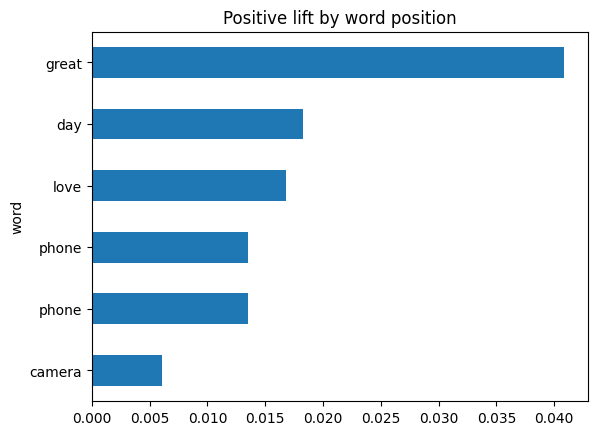

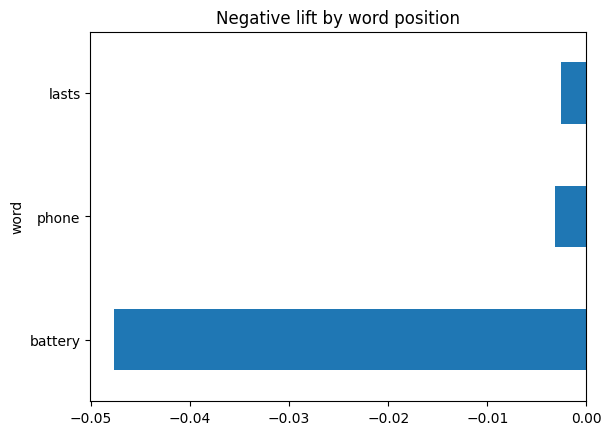

,position,word,lift
0,0,love,0.016790
1,1,phone,0.013487
2,2,phone,0.013487
3,3,camera,0.006099
4,4,great,0.040867
5,5,phone,-0.003202
6,6,battery,-0.047688
7,7,lasts,-0.002597
8,8,day,0.018245


In [5]:
# Lift by position: "phone" occurs at three positions and each occurrence
# is removed and scored separately (the old groupby('word') code could not do this).
score, lift = persona("I love my phone, my phone camera is great and my phone battery lasts all day")
lift

# Evaluation — a labelled dataset, kept separate from the dictionary

The original notebook "tested" the function on a handful of example messages
with no labels and no held-out data — and several of those examples were
built out of dictionary words, which under the old per-word max-cosine design
guaranteed inflated scores. Below is a hand-labelled coursework dataset
(**64 tech / 64 non-tech messages, 128 total**). It started at 48 messages,
which left only 10 in the test split — accuracy then moves in steps of 0.1
and the validation-chosen threshold is unstable — so round 2 expanded it to
128, giving a 26-message test split. It is still small and hand-written;
treat the metrics as indicative, not precise. Rules enforced by the next
cell:

- **No message is a dictionary entry**, and the dictionary is used only to
  build the prototype — it is never part of the train/validation/test data.
- The split is stratified, with a fixed seed; the threshold is chosen on the
  **validation** split only, and the **test** split is scored once.

In [6]:
LABELED = [
    # --- tech (1) ---
    ("My laptop battery drains fast since the latest software update", 1),
    ("I spent the weekend building a gaming pc with a new graphics card", 1),
    ("The new iphone camera takes amazing photos in low light", 1),
    ("Our team migrated the database to the cloud last week", 1),
    ("I need a mechanical keyboard for long coding sessions", 1),
    ("The bluetooth headphones keep disconnecting from my phone", 1),
    ("He is studying machine learning and data science at university", 1),
    ("The wifi router needs a firmware update to fix the speed", 1),
    ("I bought a tablet mainly for reading and watching videos", 1),
    ("Version control with git makes collaborating on code much easier", 1),
    ("The android app crashes whenever I open the settings page", 1),
    ("A solid state drive made my old computer feel new again", 1),
    ("We set up a home theater with surround speakers in the basement", 1),
    ("The sensor in the smartwatch tracks my heart rate all day", 1),
    ("She develops mobile apps for a software company downtown", 1),
    ("Online gaming with friends is how I spend most weekends", 1),
    ("The printer at work keeps jamming on the top floor", 1),
    ("Artificial intelligence tools now help doctors read scans", 1),
    ("I charge my phone overnight so it is full in the morning", 1),
    ("Streaming the match on my television beats watching on a small screen", 1),
    ("Backing up photos to cloud storage saved me when my drive failed", 1),
    ("The gaming tournament finals went to a deciding fifth map", 1),
    ("A wireless mouse and a second monitor improved my desk setup", 1),
    ("Learning to code in python opened up a career in technology", 1),
    # --- tech (round 2 additions) ---
    ("My phone battery swelled up, so I booked a repair at the store", 1),
    ("The new graphics driver fixed the stuttering in every game I tried", 1),
    ("She backs up her laptop to an external drive every Friday", 1),
    ("Our office switched to fibre broadband and video calls stopped freezing", 1),
    ("I paired the wireless earbuds with my tablet in seconds", 1),
    ("The code review caught a bug before the release went out", 1),
    ("He built a small robot that follows a line drawn on the floor", 1),
    ("The smart tv keeps asking me to sign in to streaming apps", 1),
    ("A cracked screen protector is much cheaper than a cracked screen", 1),
    ("The conference talk on quantum computing drew a huge crowd", 1),
    ("I use two-factor authentication on all my important accounts", 1),
    ("The drone footage of the coastline looks stunning in 4k", 1),
    ("My mechanical keyboard has swappable switches for a softer feel", 1),
    ("The startup's app reached a million downloads in its first year", 1),
    ("Uploading the video took an hour on our slow connection", 1),
    ("The IT team replaced the faulty server over the weekend", 1),
    ("She is learning javascript to build interactive websites", 1),
    ("The noise cancelling headphones made the long flight much quieter", 1),
    ("I cleared the browser cache and the page finally loaded properly", 1),
    ("The fitness tracker buzzes when I have sat still for too long", 1),
    ("A password manager generates a unique login for every site", 1),
    ("The 3d printer finished the prototype part overnight", 1),
    ("My old phone does not support the latest operating system", 1),
    ("The update did not fix the battery drain on my tablet", 1),
    ("I cannot connect my speakers to the new television", 1),
    ("The webcam image looks blurry in low light on video calls", 1),
    ("He overclocked his processor to squeeze out more performance", 1),
    ("The cloud photo library syncs across all of my devices", 1),
    ("A vpn lets me work securely from the airport lounge", 1),
    ("The game crashed right before the final boss fight", 1),
    ("She soldered a loose wire inside the old radio", 1),
    ("The spreadsheet app now suggests formulas as I type", 1),
    ("I replaced the thermal paste and the laptop runs cooler now", 1),
    ("The smartwatch warned him about an irregular heartbeat", 1),
    ("Developers pushed a hotfix for the login bug late last night", 1),
    ("The router's guest network keeps visitors off our main wifi", 1),
    ("My e-reader holds hundreds of books in one tiny device", 1),
    ("The security camera sends an alert when it detects motion", 1),
    ("He collects vintage computers and restores them as a hobby", 1),
    ("The satellite carried a new weather monitoring payload into orbit", 1),
    # --- non-tech (0) ---
    ("This world is a better place without terrorism and violence", 0),
    ("Health is wealth, so eat green vegetables and exercise daily", 0),
    ("This world is a better place without diseases that lead to death", 0),
    ("The garden needs watering before the tomatoes will grow", 0),
    ("She baked a chocolate cake for her daughter's birthday party", 0),
    ("The train to the city was delayed by heavy snow this morning", 0),
    ("We are planning a beach holiday with the whole family in June", 0),
    ("The novel's final chapter tied up every loose end beautifully", 0),
    ("Regular exercise and enough sleep keep my energy up", 0),
    ("The committee debated the new housing policy for three hours", 0),
    ("Fresh basil and tomatoes make a simple pasta sauce", 0),
    ("The museum's new exhibition covers two centuries of painting", 0),
    ("Interest rates rose again, worrying first-time home buyers", 0),
    ("The puppy learned to sit and stay within a week", 0),
    ("Rain flooded several streets in the old part of town", 0),
    ("He practices the piano for an hour before school every day", 0),
    ("The farmers market sells honey, cheese and fresh bread", 0),
    ("Meditation in the morning helps me stay calm under pressure", 0),
    ("The football coach praised the team's defending after the match", 0),
    ("Volunteers served soup at the shelter throughout the winter", 0),
    ("The recipe calls for two cups of flour and a pinch of salt", 0),
    ("Grandma tells wonderful stories about growing up in the village", 0),
    ("The orchestra performed Beethoven to a full concert hall", 0),
    ("I have no interest in computers or phones at all", 0),
    # --- non-tech (round 2 additions) ---
    ("The mouse ran across the kitchen floor and hid behind the bin", 0),
    ("An apple a day is my grandfather's favourite saying", 0),
    ("The windows in the cottage were painted a pale blue last spring", 0),
    ("She drives an old diesel car that rattles on steep hills", 0),
    ("The choir rehearsed the hymn twice before the Sunday service", 0),
    ("I do not like waking up before sunrise in the winter", 0),
    ("There is no rice left, so we are having potatoes instead", 0),
    ("The hiking trail crosses two rivers and a pine forest", 0),
    ("He never misses his grandmother's Sunday roast", 0),
    ("The library book club meets on the first Tuesday of the month", 0),
    ("Fresh paint made the hallway smell strange for days", 0),
    ("The toddler stacked the wooden blocks and knocked them down laughing", 0),
    ("Our neighbour's cat sleeps on the porch every afternoon", 0),
    ("The wedding photos were taken in the botanical gardens", 0),
    ("She knits scarves for the charity shop in her spare time", 0),
    ("The bus was crowded, so I walked the last mile home", 0),
    ("A thunderstorm brought down fences all over the farm", 0),
    ("The chef tasted the soup and added a little more pepper", 0),
    ("We watched the sunset from the lighthouse steps", 0),
    ("The history exam covered the Roman empire in detail", 0),
    ("His bicycle chain snapped halfway up the hill", 0),
    ("The garden club swapped seedlings at the spring fair", 0),
    ("I cannot swim, so I stayed at the shallow end of the pool", 0),
    ("The postman delivered a parcel for the house next door", 0),
    ("She keeps a diary of the birds she spots each spring", 0),
    ("The old bridge will close for repairs next month", 0),
    ("My umbrella flipped inside out in the strong wind", 0),
    ("The bakery sells out of croissants by nine most days", 0),
    ("They adopted a rescue dog from the local shelter", 0),
    ("The piano tuner comes once a year, just before the recital", 0),
    ("Snow covered the rooftops and the parked cars by dawn", 0),
    ("The fishermen set out before the harbour lights came on", 0),
    ("Her speech at the graduation ceremony moved everyone to tears", 0),
    ("The committee could not agree on the new park design", 0),
    ("A bowl of hot soup is perfect on a cold evening", 0),
    ("The children built a den out of cushions and blankets", 0),
    ("He watered the houseplants while we were away on holiday", 0),
    ("The market stall sells handmade soap and beeswax candles", 0),
    ("I lost my gloves somewhere on the train last week", 0),
    ("The village fete had a raffle and a bake sale on the green", 0),
]

messages = [m for m, _ in LABELED]
labels = np.array([y for _, y in LABELED])

# Separation checks: dictionary != evaluation data.
dict_set = set(ss.DICTIONARY)
assert not any(m.lower() in dict_set for m in messages), "a test message is a dictionary entry"
assert len(set(messages)) == len(messages), "duplicate labelled message"
print(f"{len(messages)} labelled messages: {labels.sum()} tech / {(labels == 0).sum()} non-tech")

128 labelled messages: 64 tech / 64 non-tech


In [7]:
# Stratified train / validation / test split, fixed seed.
# Threshold is tuned on validation ONLY; test is touched once, at the end.
X_train, X_tmp, y_train, y_tmp = train_test_split(
    messages, labels, test_size=0.40, random_state=42, stratify=labels
)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.50, random_state=42, stratify=y_tmp
)
print(f"train {len(X_train)} / validation {len(X_val)} / test {len(X_test)}")

train 76 / validation 26 / test 26


## Three scorers

1. **Whole-message transformer score** — cosine between the whole-message
   embedding and the dictionary prototype (the rebuilt method).
2. **TF-IDF cosine baseline** — vectoriser fitted on the dictionary entries;
   a message scores its cosine against the dictionary *prototype* (the
   centroid of the entries' TF-IDF vectors). Round 1's version took the
   maximum cosine against individual entries, so a message containing one
   exact dictionary word scored 1.0 — the same artefact removed from the
   transformer side. Against the centroid that cannot happen.
3. **Averaged word-vector baseline** — preprocessed words embedded in one
   batched call, averaged, compared with the same prototype. This discards
   word order and context, which is exactly the contrast of interest.

Every scorer runs on all three splits; embeddings for each scorer are
computed in batched calls, not per-pair loops.

In [8]:
def all_scores(texts):
    return {
        "transformer (whole message)": ss.interest_scores(texts, encoder, prototype),
        "tfidf cosine": ss.tfidf_scores(texts),
        "averaged word vectors": ss.averaged_word_vector_scores(texts, encoder, prototype),
    }

scores = {name: all_scores(texts) for name, texts in
          [("train", X_train), ("val", X_val), ("test", X_test)]}
scores["train"].keys()

dict_keys(['transformer (whole message)', 'tfidf cosine', 'averaged word vectors'])

In [9]:
# Choose each method's threshold on the VALIDATION split (best F1).
thresholds = {}
for method in scores["val"]:
    cand = np.unique(np.round(scores["val"][method], 3))
    best_t, best_f1 = 0.5, -1.0
    for t in cand:
        f1 = f1_score(y_val, (scores["val"][method] >= t).astype(int), zero_division=0)
        if f1 > best_f1:
            best_t, best_f1 = float(t), f1
    thresholds[method] = best_t
    print(f"{method}: validation threshold = {best_t:.3f} (validation F1 = {best_f1:.3f})")

transformer (whole message): validation threshold = 0.136 (validation F1 = 0.833)
tfidf cosine: validation threshold = 0.000 (validation F1 = 0.667)
averaged word vectors: validation threshold = 0.658 (validation F1 = 0.923)


In [10]:
# Score the TEST split once, with the validation-chosen thresholds.
rows = []
for method, test_scores in scores["test"].items():
    pred = (test_scores >= thresholds[method]).astype(int)
    rows.append({
        "method": method,
        "accuracy": accuracy_score(y_test, pred),
        "AUC": roc_auc_score(y_test, test_scores),
        "F1": f1_score(y_test, pred, zero_division=0),
    })
# Majority-class reference point for the test split.
majority_acc = max(np.mean(y_test), 1 - np.mean(y_test))
print(f"Majority-class baseline accuracy on test: {majority_acc:.3f}")
pd.DataFrame(rows)

Majority-class baseline accuracy on test: 0.500


,method,accuracy,AUC,F1
0,transformer (whole message),0.807692,0.911243,0.782609
1,tfidf cosine,0.500000,0.837278,0.666667
2,averaged word vectors,0.961538,0.994083,0.962963


# Conclusion (corrected)

The original conclusion claimed interest scores of "85% or higher" for
tech-related messages and "75% to 82%" for unrelated ones. **Its own examples
contradict that:** a non-tech message about terrorism was reported at about
82% (82.35% in the run output) — at/above the top of the claimed non-tech
range and close to the tech examples (87–90%) — and the other non-tech
examples scored 78.4% and 78.8%, inside the same narrow band as everything
else. With scores that close together, no threshold separates the two groups
well, which is what the evaluation above now measures directly instead of
asserting ranges.

The original text also said "BERT is not very good in predicting the
semantics of different sentences". That blamed the model for a **design
choice in this project**: the original code embedded single words, took each
word's *maximum* cosine against the dictionary (so exact dictionary matches
scored 1.0), and averaged — a method that discards sentence context by
construction. Modern sentence-transformer checkpoints are trained precisely
for sentence-level semantics; whether this persona score separates tech from
non-tech messages is an empirical question, answered by the held-out
accuracy / AUC / F1 table above (computed when the notebook runs) rather
than by the anecdotal examples.

Limitations: the labelled dataset is hand-written for coursework and, even
after the round-2 expansion from 48 to 128 messages (26 in the test split),
still small — the metrics have wide uncertainty and the validation-chosen
threshold is only as good as those 128 messages. A larger, independently
labelled dataset is the obvious next step.

# Next Steps

- Grow the labelled dataset (ideally messages written/collected independently
  of the dictionary) and re-tune the threshold.
- Try other sentence encoders (larger MiniLM / MPNet checkpoints) and compare
  on the same split, using the same threshold-on-validation protocol.
- Compare against the classical baselines already included here (TF-IDF,
  averaged word vectors) before assuming the transformer is needed.
- Classic static embeddings (word2vec, GloVe, fastText) can be added as
  further averaged-vector baselines under the same evaluation.